<a href="https://colab.research.google.com/github/srinivathini1712-commits/Student_performance_analysis/blob/main/parking_occupancy_forcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Parking Occupancy Forecasting Project")
print("Libraries imported successfully!")


Parking Occupancy Forecasting Project
Libraries imported successfully!


In [ ]:


# STEP 1: Import libraries and upload dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Saving parking-occupancy-data-realtime.csv to parking-occupancy-data-realtime (1).csv
Dataset loaded successfully!
Dataset shape: (49585, 9)

Column names:
['timestamp', 'Lot', 'Occupancy level', 'Day of week', 'Hour of day', 'parking_limit', 'minute_of_day', 'parking_hours_9am_6pm', 'street_name']

First 5 rows:


,timestamp,Lot,Occupancy level,Day of week,Hour of day,parking_limit,minute_of_day,parking_hours_9am_6pm,street_name
0,2023-12-21T20:30:09+05:30,1,56.250,Friday,2.0,1p,0.0,N,Macquarie Street
1,2023-12-21T20:15:08+05:30,1,43.750,Friday,1.0,1p,45.0,N,Macquarie Street
2,2023-12-21T20:00:05+05:30,1,40.625,Friday,1.0,1p,30.0,N,Macquarie Street
3,2023-12-21T19:45:09+05:30,1,46.875,Friday,1.0,1p,15.0,N,Macquarie Street
4,2023-12-21T19:30:07+05:30,1,53.125,Friday,1.0,1p,0.0,N,Macquarie Street


In [ ]:


# STEP 3: Check the dataset

print("Dataset Information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nOccupancy level summary:")
print(df["Occupancy level"].describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49585 entries, 0 to 49584
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   timestamp              49584 non-null  object 
 1   Lot                    49585 non-null  int64  
 2   Occupancy level        49585 non-null  float64
 3   Day of week            49584 non-null  object 
 4   Hour of day            49584 non-null  float64
 5   parking_limit          49585 non-null  object 
 6   minute_of_day          49584 non-null  float64
 7   parking_hours_9am_6pm  49585 non-null  object 
 8   street_name            49585 non-null  object 
dtypes: float64(3), int64(1), object(5)
memory usage: 3.4+ MB

Missing values in each column:
timestamp                1
Lot                      0
Occupancy level          0
Day of week              1
Hour of day              1
parking_limit            0
minute_of_day            1
parking_hours_9a

In [ ]:

# STEP 4: Handle missing values

# Convert timestamp into datetime format
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

# Remove rows where timestamp is missing
df = df.dropna(subset=["timestamp"]).copy()

# Fill missing values in time-related columns
df["Day of week"] = df["Day of week"].fillna(
    df["timestamp"].dt.day_name()
)

df["Hour of day"] = df["Hour of day"].fillna(
    df["timestamp"].dt.hour
)

df["minute_of_day"] = df["minute_of_day"].fillna(
    df["timestamp"].dt.hour * 60
    + df["timestamp"].dt.minute
)

print("Missing values handled successfully!")
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nUpdated dataset shape:", df.shape)


Missing values handled successfully!

Missing values after cleaning:
timestamp                0
Lot                      0
Occupancy level          0
Day of week              0
Hour of day              0
parking_limit            0
minute_of_day            0
parking_hours_9am_6pm    0
street_name              0
dtype: int64

Updated dataset shape: (49584, 9)


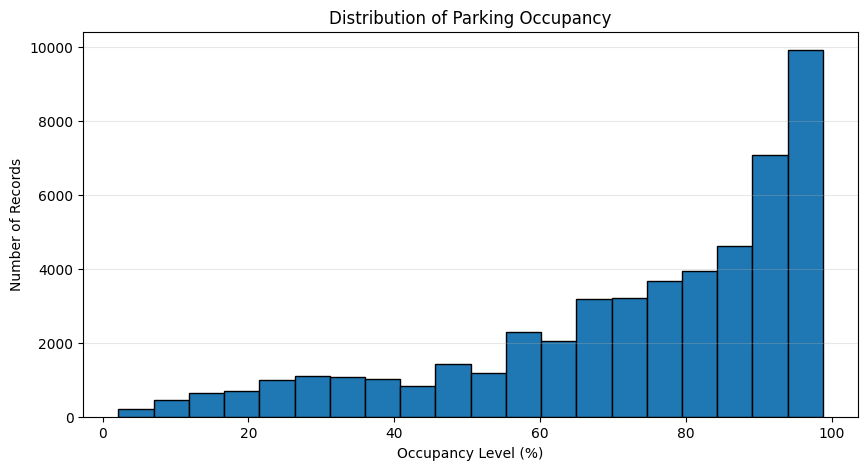

In [ ]:

# STEP 5: Visualize parking occupancy

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["Occupancy level"], bins=20, edgecolor="black")

plt.title("Distribution of Parking Occupancy")
plt.xlabel("Occupancy Level (%)")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.3)
plt.show()


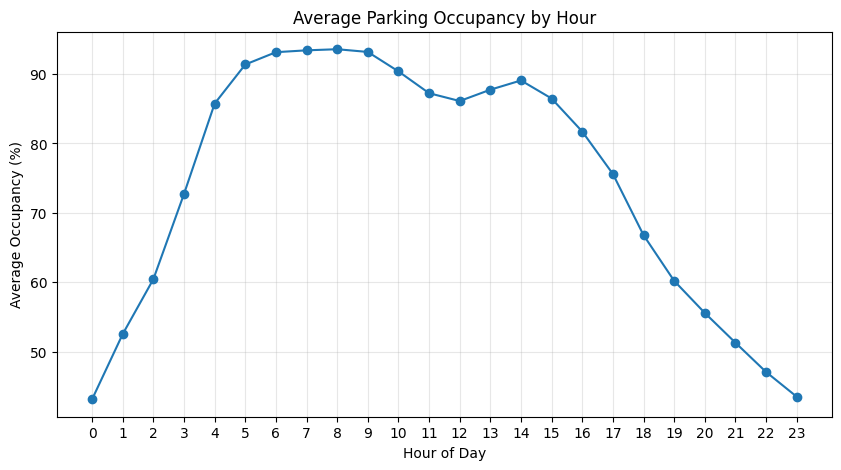

In [ ]:

# STEP 6: Average parking occupancy by hour

df["Hour"] = df["timestamp"].dt.hour

hourly_occupancy = df.groupby("Hour")["Occupancy level"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_occupancy.index, hourly_occupancy.values, marker="o")

plt.title("Average Parking Occupancy by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Occupancy (%)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

# STEP 7: Prepare data for future occupancy forecasting

# Sort records by timestamp
df = df.sort_values("timestamp").reset_index(drop=True)

# Create a target for occupancy 15 minutes later
df["Future_Occupancy"] = df["Occupancy level"].shift(-1)

# Check time intervals between consecutive records
df["Time_Difference"] = df["timestamp"].diff().dt.total_seconds() / 60

print("Data sorted by timestamp.")
print("\nTime interval summary (minutes):")
print(df["Time_Difference"].describe())

print("\nSample forecasting data:")
display(
    df[["timestamp", "Occupancy level",
        "Future_Occupancy", "Time_Difference"]].head(10)
)


Data sorted by timestamp.

Time interval summary (minutes):
count    49583.000000
mean         9.668781
std         67.855963
min          0.000000
25%          0.000000
50%         14.916667
75%         15.016667
max      14400.033333
Name: Time_Difference, dtype: float64

Sample forecasting data:


,timestamp,Occupancy level,Future_Occupancy,Time_Difference
0,2023-01-22 22:22:58+05:30,93.75,93.75,NaN
1,2023-01-22 22:23:51+05:30,93.75,93.75,0.883333
2,2023-01-22 22:24:29+05:30,93.75,97.50,0.633333
3,2023-01-23 09:10:27+05:30,97.50,97.50,645.966667
4,2023-01-23 09:14:13+05:30,97.50,95.00,3.766667
5,2023-01-23 09:16:14+05:30,95.00,95.00,2.016667
6,2023-01-23 09:17:18+05:30,95.00,95.00,1.066667
7,2023-01-23 09:18:12+05:30,95.00,93.75,0.900000
8,2023-01-23 09:21:45+05:30,93.75,93.75,3.550000
9,2023-01-23 09:22:29+05:30,93.75,92.50,0.733333


In [ ]:

# STEP 7A: Create a proper 15-minute-ahead target

# Keep the current occupancy and target time
base = df[["timestamp", "Lot", "street_name",
           "Occupancy level"]].copy()

base["target_time"] = base["timestamp"] + pd.Timedelta(minutes=15)

# Prepare future records
future = df[["timestamp", "Lot", "street_name",
             "Occupancy level"]].copy()

future = future.rename(columns={
    "timestamp": "matched_time",
    "Occupancy level": "Future_Occupancy"
})

# Match the closest observation around 15 minutes later
base = base.sort_values("target_time")
future = future.sort_values("matched_time")

df = pd.merge_asof(
    base,
    future,
    left_on="target_time",
    right_on="matched_time",
    by=["Lot", "street_name"],
    direction="nearest",
    tolerance=pd.Timedelta(minutes=5)
)

# Keep records with a valid future target
df = df.dropna(subset=["Future_Occupancy"]).copy()

print("15-minute forecasting target created!")
print("Usable records:", len(df))
print("\nSample output:")

display(df[[
    "timestamp", "Occupancy level",
    "target_time", "matched_time", "Future_Occupancy"
]].head(10))


15-minute forecasting target created!
Usable records: 47604

Sample output:


,timestamp,Occupancy level,target_time,matched_time,Future_Occupancy
3,2023-01-23 09:10:27+05:30,97.50,2023-01-23 09:25:27+05:30,2023-01-23 09:26:09+05:30,92.50
4,2023-01-23 09:14:13+05:30,97.50,2023-01-23 09:29:13+05:30,2023-01-23 09:28:54+05:30,92.50
5,2023-01-23 09:16:14+05:30,95.00,2023-01-23 09:31:14+05:30,2023-01-23 09:30:53+05:30,92.50
6,2023-01-23 09:17:18+05:30,95.00,2023-01-23 09:32:18+05:30,2023-01-23 09:31:51+05:30,92.50
7,2023-01-23 09:18:12+05:30,95.00,2023-01-23 09:33:12+05:30,2023-01-23 09:31:51+05:30,92.50
8,2023-01-23 09:21:45+05:30,93.75,2023-01-23 09:36:45+05:30,2023-01-23 09:31:51+05:30,92.50
18,2023-01-23 10:15:06+05:30,93.75,2023-01-23 10:30:06+05:30,2023-01-23 10:30:12+05:30,96.25
19,2023-01-23 10:30:12+05:30,96.25,2023-01-23 10:45:12+05:30,2023-01-23 10:45:07+05:30,98.75
20,2023-01-23 10:45:07+05:30,98.75,2023-01-23 11:00:07+05:30,2023-01-23 11:00:12+05:30,90.00
21,2023-01-23 11:00:12+05:30,90.00,2023-01-23 11:15:12+05:30,2023-01-23 11:15:07+05:30,87.50


In [ ]:

# STEP 8: Prepare features and split the data

from sklearn.model_selection import train_test_split

# Create useful time-based features
df["Hour"] = df["timestamp"].dt.hour
df["Day_Number"] = df["timestamp"].dt.dayofweek

# Select input features
features = [
    "Occupancy level",
    "Hour",
    "Day_Number",
    "Lot"
]

X = df[features]
y = df["Future_Occupancy"]

# Split chronologically: earlier data for training,
# later data for testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Feature preparation completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", features)
print("Target: Occupancy after approximately 15 minutes")


Feature preparation completed!
Training records: 38083
Testing records: 9521
Input features: ['Occupancy level', 'Hour', 'Day_Number', 'Lot']
Target: Occupancy after approximately 15 minutes


In [ ]:

# STEP 9: Train the Random Forest Regression model

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Random Forest model trained successfully!
Training records: 38083
Testing records: 9521


In [ ]:


# STEP 10A: Predict future parking occupancy

# Check whether the test data is available
if 'X_test' in globals() and 'y_test' in globals() and 'model' in globals():

    # Generate predictions
    y_pred = model.predict(X_test)

    print("Predictions generated successfully!")

    print("\nFirst 10 actual occupancy values:")
    print(y_test.head(10).values if hasattr(y_test, 'head') else y_test[:10])

    print("\nFirst 10 predicted occupancy values:")
    print(y_pred[:10])

else:
    print("Error: model, X_test, or y_test is not defined.")
    print("Run the data splitting and model training cells first.")


Error: model, X_test, or y_test is not defined.
Run the data splitting and model training cells first.


In [ ]:


# STEP 11: Evaluate the Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


NameError: name 'y_pred' is not defined

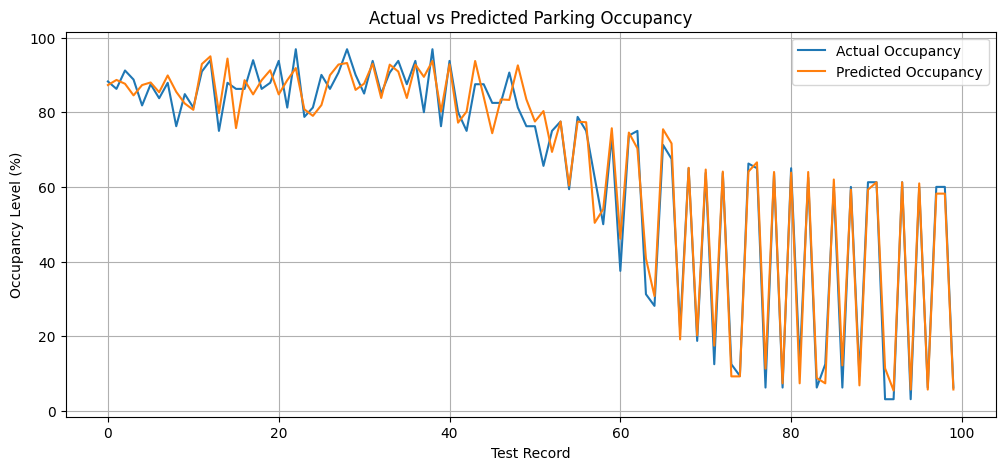

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Occupancy"
)

plt.plot(
    y_pred[:100],
    label="Predicted Occupancy"
)

plt.title("Actual vs Predicted Parking Occupancy")
plt.xlabel("Test Record")
plt.ylabel("Occupancy Level (%)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def classify_occupancy(value):
    if value < 40:
        return "Low"
    elif value < 70:
        return "Medium"
    else:
        return "High"

# Classify predicted occupancy
predicted_category = [
    classify_occupancy(value) for value in y_pred
]

# Display first 10 predictions
results = pd.DataFrame({
    "Actual Occupancy": y_test.values,
    "Predicted Occupancy": y_pred,
    "Predicted Category": predicted_category
})

print("PARKING OCCUPANCY CLASSIFICATION")
print("--------------------------------")
print(results.head(10).round(2).to_string(index=False))

PARKING OCCUPANCY CLASSIFICATION
--------------------------------
 Actual Occupancy  Predicted Occupancy Predicted Category
            88.24                87.28               High
            86.25                88.65               High
            91.18                87.62               High
            88.75                84.51               High
            81.82                87.28               High
            87.50                87.97               High
            83.75                85.35               High
            87.88                89.85               High
            76.25                85.46               High
            84.85                82.34               High


In [ ]:
print("PARKING OCCUPANCY FORECASTING")
print("=" * 35)

print(f"Dataset records used: {len(df)}")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")

print("\nMODEL PERFORMANCE")
print("-" * 25)
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

print("\nOCCUPANCY CATEGORY COUNTS")
print("-" * 25)
print(results["Predicted Category"].value_counts())

print("\nProject model execution completed!")

PARKING OCCUPANCY FORECASTING
Dataset records used: 47604
Training records: 38083
Testing records: 9521

MODEL PERFORMANCE
-------------------------
MAE  : 4.48
RMSE : 6.48
R2 Score: 0.9323

OCCUPANCY CATEGORY COUNTS
-------------------------
Predicted Category
High      5722
Medium    2336
Low       1463
Name: count, dtype: int64

Project model execution completed!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Features and target (using corrected column name 'Future_Occupancy')
X = df[['Occupancy level', 'Hour', 'Day_Number', 'Lot']]
y = df['Future_Occupancy']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False
)

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predict occupancy
y_pred = model.predict(X_test)

# Keep predictions between 0 and 100
y_pred = y_pred.clip(0, 100)

print("Model trained and predictions generated successfully!")

Model trained and predictions generated successfully!


In [ ]:

# PARKING OCCUPANCY FORECASTING USING MACHINE LEARNING
# Complete Program

import pandas as pd
import numpy as np
from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score
)

# STEP 1: Upload dataset
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# STEP 2: Check required columns
required = ['timestamp', 'Lot', 'street_name', 'Occupancy level']

if not all(col in df.columns for col in required):
    raise ValueError(
        "Dataset must contain: " + str(required) +
        "\nAvailable columns: " + str(df.columns.tolist())
    )

# STEP 3: Preprocess data
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['Occupancy level'] = pd.to_numeric(
    df['Occupancy level'], errors='coerce'
)

df = df.dropna(subset=required).copy()
df = df.dropna(subset=['Occupancy level'])
df = df.sort_values('timestamp').reset_index(drop=True)

# STEP 4: Create 15-minute future occupancy target
future = df[['timestamp', 'Lot', 'street_name',
             'Occupancy level']].copy()

future = future.rename(columns={
    'timestamp': 'future_time',
    'Occupancy level': 'Future_Occupancy'
})

df['target_time'] = df['timestamp'] + pd.Timedelta(minutes=15)

df = df.sort_values('target_time')
future = future.sort_values('future_time')

df = pd.merge_asof(
    df,
    future,
    left_on='target_time',
    right_on='future_time',
    by=['Lot', 'street_name'],
    direction='nearest',
    tolerance=pd.Timedelta(minutes=5)
)

df = df.dropna(subset=['Future_Occupancy']).copy()

# STEP 5: Create time-based features
df['Hour'] = df['timestamp'].dt.hour
df['Day_Number'] = df['timestamp'].dt.dayofweek

# Convert parking lot IDs into numeric codes
df['Lot_Code'] = pd.factorize(df['Lot'])[0]

# STEP 6: Select features and target
X = df[['Occupancy level', 'Hour', 'Day_Number', 'Lot_Code']]
y = df['Future_Occupancy']

# STEP 7: Split data chronologically (80% train, 20% test)
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Not enough data to train and test the model.")

# STEP 8: Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Model trained successfully!")

# STEP 9: Predict future occupancy
y_pred = np.clip(model.predict(X_test), 0, 100)

print("\nFirst 10 Actual Occupancy Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Occupancy Values:")
print(np.round(y_pred[:10], 2))

# STEP 10: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION RESULTS")
print("------------------------")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

# STEP 11: Calculate Low / Medium / High category accuracy
def classify_occupancy(value):
    if value < 40:
        return "Low"
    elif value < 70:
        return "Medium"
    return "High"

actual_categories = [
    classify_occupancy(v) for v in y_test
]
predicted_categories = [
    classify_occupancy(v) for v in y_pred
]

accuracy = accuracy_score(
    actual_categories, predicted_categories
)

print(f"\nOccupancy Category Accuracy: {accuracy * 100:.2f}%")
print("\nProgram completed successfully!")


Saving parking-occupancy-data-realtime.csv to parking-occupancy-data-realtime (2).csv
Model trained successfully!

First 10 Actual Occupancy Values:
[88.23529412 86.25       91.17647059 88.75       81.81818182 87.5
 83.75       87.87878788 76.25       84.84848485]

First 10 Predicted Occupancy Values:
[87.29 88.65 87.62 84.51 87.29 87.97 85.35 89.83 85.46 82.37]

MODEL EVALUATION RESULTS
------------------------
MAE: 4.48
RMSE: 6.48
R2 Score: 0.9323

Occupancy Category Accuracy: 90.58%

Program completed successfully!
